<h1 style="text-align: center"> Pandas Library </h1>

In [1]:
import pandas as pd 

In [2]:
# Import an example DataBase
# Define the filename
filename = r'../../AIDataFactory/pdf-files/Python/datasets/lecture_7_dataset/titanic_dataset.csv'
# Read the file
df6 = pd.read_csv(filename)
#print the first 5 rows
df6.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Advanced Operations with DataFrames

### **value_counts:** is used to count the unique values in Series or DataFrame columns.
Example: We want to see the cumulative data for the parent-children.

In [3]:
parent_children_density_form = df6['Parch'].value_counts(dropna=False)
parent_children_density_form

Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64

### **Apply function: `.apply(func, axis)`**: The apply function allows you to apply a function along the axis of the DataFrame(either rows or columns). It’s useful for **transforming** data or applying custom operations.

In [13]:
def family_size(row)-> int :
    """This function add all the family members """
    return row['SibSp'] + row['Parch'] + 1

#Create a Family Size column
df6['Family_Size'] = df6.apply(family_size, axis=1) # Need the axis = 1 to make row by row processes. 
df6.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family_Size
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1


### **Merge two DataFrames: `.merge(df_name1, df_name2, on="column_name", how= "inner")`** Merging is used to combine two DataFrames based on a common key or column. Similar to a SQL `join`.

Example:

In [4]:
# Creating the first DataFrame
students = pd.DataFrame({
    'student_id': [1, 2, 3, 4],
    'name': ['Alice', 'Bob', 'Charlie', 'David']
})

# Creating the second DataFrame
grades = pd.DataFrame({
    'student_id': [1, 2, 3, 5],
    'grade': ['A', 'B', 'C', 'D']
})

# Merging on 'student_id' column with the inner join.
merged_df = pd.merge(students, grades, on='student_id', how='inner')
print("Merged DataFrame:\n", merged_df)

Merged DataFrame:
    student_id     name grade
0           1    Alice     A
1           2      Bob     B
2           3  Charlie     C


### **Concat two DataFrames: `.concat([df_name1, df_name2], axis=0)`** Concatenation is used to stack DataFrames either vertically (adding rows) or horizontally (adding columns)

Example:

In [5]:
# Creating the first DataFrame
group_a = pd.DataFrame({
    'student_id': [1, 2, 3, 4],
    'name': ['Alice', 'Bob', 'Charlie', 'David'],
    'grade': ['A', 'B', 'C', 'D']
})

# Creating the second DataFrame
group_b = pd.DataFrame({
    'student_id': [5, 6, 7, 8],
    'name': ['Eleni', 'Fanis', 'George', 'Jason'],
    'grade': ['A', 'B', 'C', 'D']
})

# Concatenating the DataFrames vertically (axis=0)
concatenated_df = pd.concat([group_a, group_b],  axis=0) # Need reindexing
print("Concatenated DAtaFrame:\n", concatenated_df)

Concatenated DAtaFrame:
    student_id     name grade
0           1    Alice     A
1           2      Bob     B
2           3  Charlie     C
3           4    David     D
0           5    Eleni     A
1           6    Fanis     B
2           7   George     C
3           8    Jason     D


### **GroupBy in Pandas: `.groupby('col_name1')['col_name2']`**.mean() | .sum() etc : is used to split data into groups, apply operations (like sum, mean), and combine the results.
Example: 

In [6]:
# Creating a richer DataFrame
df = pd.DataFrame({
    'department': [
        'IT', 'HR', 'IT', 'HR', 'Finance',
        'IT', 'Finance', 'HR', 'Marketing', 'Marketing',
        'Finance', 'IT', 'HR', 'Marketing'
    ],
    'employee': [
        'Alice', 'Bob', 'Charlie', 'David', 'Eve',
        'Frank', 'Grace', 'Helen', 'Ivy', 'Jack',
        'Kevin', 'Laura', 'Mike', 'Nina'
    ],
    'salary': [
        60000, 50000, 70000, 55000, 65000,
        72000, 68000, 52000, 58000, 60000,
        71000, 75000, 53000, 62000
    ]
})

# Grouping by department and calculating average salary
grouped_df = df.groupby('department')['salary'].mean()
print("Grouped DataFrame:\n", grouped_df)
# We can use and aggregesion for many measures at one. 
grouped_df_agg = df.groupby('department')['salary'].agg(["count", "sum", "mean"])
print("\n\nGrouped DataFrame:\n", grouped_df_agg)

Grouped DataFrame:
 department
Finance      68000.0
HR           52500.0
IT           69250.0
Marketing    60000.0
Name: salary, dtype: float64


Grouped DataFrame:
             count     sum     mean
department                        
Finance         3  204000  68000.0
HR              4  210000  52500.0
IT              4  277000  69250.0
Marketing       3  180000  60000.0


Complicated but useful example: 

In [7]:
# Typically we make transformation of our data.
df6_tranform1 = df6.groupby(["Pclass", "Sex"]).agg(
    Survival_Rate=("Survived", "mean"),
    Average_Age=("Age", "mean"),
    Total_Passengers=("PassengerId", "count")
).reset_index()
df6_tranform1

,Pclass,Sex,Survival_Rate,Average_Age,Total_Passengers
0,1,female,0.968085,34.611765,94
1,1,male,0.368852,41.281386,122
2,2,female,0.921053,28.722973,76
3,2,male,0.157407,30.740707,108
4,3,female,0.500000,21.750000,144
5,3,male,0.135447,26.507589,347


 <h2 style = "text-align: center"> <b>Simple Plots with Pandas</b> </h2>
 <h3><b>Bar Plot</b></h3>

Example:


<Axes: title={'center': 'Monthly Sales Comparison Product A, Product B and C'}, xlabel='Month', ylabel='Sales'>

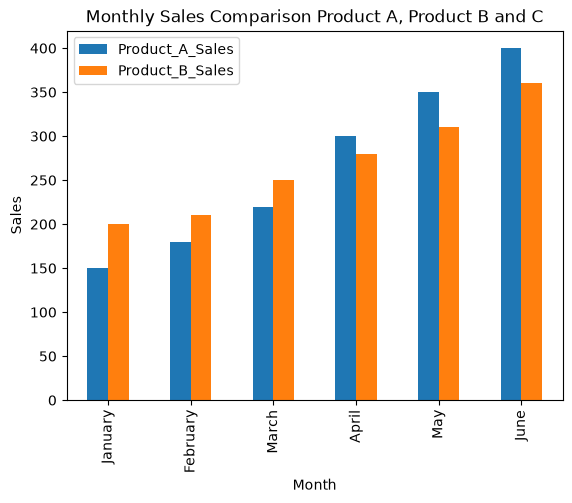

In [9]:
# Creating the DataFrame
data = {
    'Month': ['January', 'February', 'March', 'April', 'May', 'June'],
    'Product_A_Sales': [150, 180, 220, 300, 350, 400],
    'Product_B_Sales': [200, 210, 250, 280, 310, 360],
    'Product_C_Sales': [100, 110, 180, 350, 380, 460],
    'Product_D_Sales': [100, 110, 180, 350, 380, 460],
}
df_sales = pd.DataFrame(data)

# Set 'Month' as the index for better plotting.
df_sales= df_sales.set_index('Month') # If you don't. You can specify the column for x-axis and also the columns for y-axis.

# Bar Plot: Comparing Sales of Product A and Product B for each month.
df_sales.plot(
    kind='bar',
    # x='Month', # We don't need this because we have put set_index before.
    y = ['Product_A_Sales', 'Product_B_Sales'], 
    title= "Monthly Sales Comparison Product A, Product B and C",
    ylabel="Sales",
    xlabel="Month")  

### **Line Plot**

<Axes: title={'center': 'Monthly Sales Comparison Product A, Product B and C'}, xlabel='Month', ylabel='Sales'>

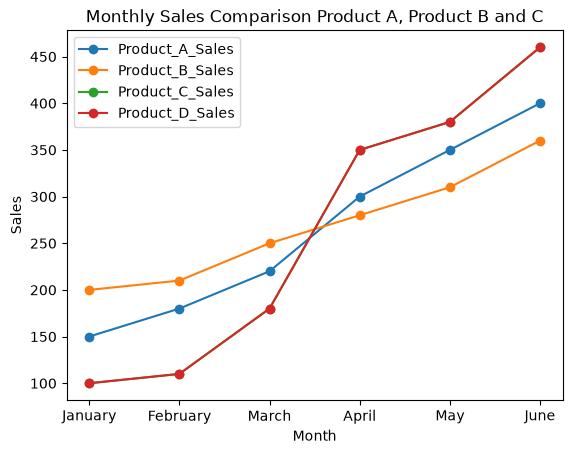

In [10]:
# Line Plot: Showing Sales over Time.
df_sales.plot(
    kind='line',
    # x='Month',
    title= "Monthly Sales Comparison Product A, Product B and C",
    ylabel="Sales",
    xlabel="Month",
    marker='o')  

### **Pie Plot**

<Axes: title={'center': 'Monthly Sales of Product A'}>

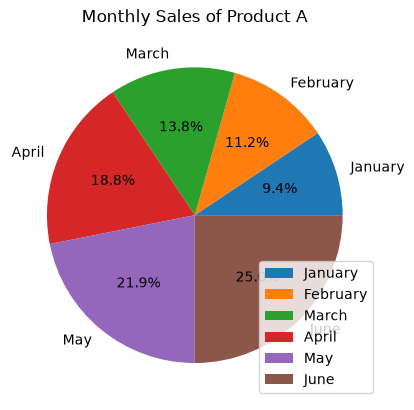

In [12]:
# Line Plot: Showing Sales over Time.
df_sales.plot(
    kind='pie',
    # x='Month',
    y= 'Product_A_Sales',
    title= "Monthly Sales of Product A",
    autopct="%1.1f%%")  

 <h2 style = "text-align: center"> <b>Exporting Data</b> </h2>
 <h3> Export to<b>CSV</b>:</h3>
 <code>df.to_csv("output_name.csv", index=False)</code>
 <h3> Export to<b>Excel:</b>:</h3>
 <code>df.to_excel("output_name.xlsx", index=False)</code>
 <h3> Export to<b>Html:</b>:</h3>
 <code>df.to_html("output_name.html", index=False)</code>

<h2 style = "text-align: center"> <b>Exercise for Practice</b> </h2>

**Load the Titanic Dataset**:
- Load the Titanic dataset into a pandas DataFrame.
- Display the first 5 rows to get a sense of the data structure.
**Basic Analysis with value_counts:**
- Use value_counts() to analyze the distribution of:
    - Passenger class (Pclass).
    - Survival status (Survived).
    - Embarkation point (Embarked).
    - Display the results to identify the most common classes, survival counts, and embarkation points.

**Create the following plots to visualize key aspects of the dataset:**
- Bar Plot: Plot the distribution of passenger classes (Pclass).
- Pie Chart: Show the percentage of passengers who survived vs. did not survive.
- Histogram: Visualize the age distribution of passengers

**Custom Calculations with the apply Method:**
- Use apply to create two new columns:
    - Age_Group: Categorize each passenger as Child (Age < 18), Adult (18 <= Age < 60), or Senior (Age >= 60).
    - Family_Size: Calculate family size as the sum of SibSp and Parch, plus 1 (to include the passenger).
    - Display the first few rows to verify the new columns.
    
**Challenge:** Using the Family_Size column, create a bar plot that shows the average survival rate for passengers
based on their family size.